In [1]:
%pip install pyts

   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.6 MB 239.9 kB/s eta 0:00:09
   -------- ------------------------------- 0.5/2.6 MB 239.9 kB/s eta 0:00:09
   -------- ------------------------------- 0.5/2.6 MB 239.9 kB/s eta 0:00:09
   ------------ --------------------------- 0.8/2.6 MB 299.7 kB/s eta 0:00:06
   ---------------- ----------------------- 1.0/2.6 MB 385.5 kB/s eta 0:00:04
   ---------------- ----------------------- 1.0/2.6 MB 385


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import matplotlib.pyplot as plt

X_normal = np.loadtxt(
    "../datasets/normalized/normal.csv",
    delimiter=","
)

print("Shape:", X_normal.shape)

signal = X_normal[0]

print("Signal shape:", signal.shape)
print("Min:", signal.min())
print("Max:", signal.max())

Shape: (100, 100000)
Signal shape: (100000,)
Min: 0.0
Max: 1.0


In [4]:
import numpy as np
import matplotlib.pyplot as plt

X_normal = np.loadtxt(
    "../datasets/normalized/normal.csv",
    delimiter=","
)

print("Shape:", X_normal.shape)

signal = X_normal[0]

print("Signal shape:", signal.shape)
print("Min:", signal.min())
print("Max:", signal.max())

Shape: (100, 100000)
Signal shape: (100000,)
Min: 0.0
Max: 1.0


In [5]:
from pyts.image import GramianAngularField

transformer_gasf = GramianAngularField(image_size=512, method="summation")
transformer_gadf = GramianAngularField(image_size=512, method="difference")

gasf = transformer_gasf.fit_transform(signal.reshape(1, -1))[0]
gadf = transformer_gadf.fit_transform(signal.reshape(1, -1))[0]

print("GASF shape:", gasf.shape)
print("GADF shape:", gadf.shape)

GASF shape: (512, 512)
GADF shape: (512, 512)


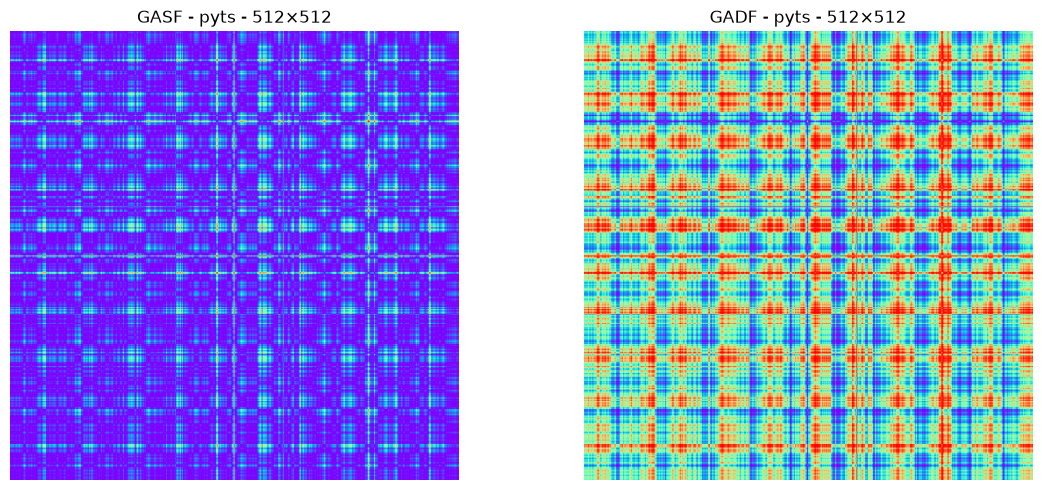

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gasf, cmap="rainbow", origin="lower")
axes[0].set_title("GASF - pyts - 512×512")
axes[0].axis("off")

axes[1].imshow(gadf, cmap="rainbow", origin="lower")
axes[1].set_title("GADF - pyts - 512×512")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
from pyts.image import GramianAngularField
import numpy as np
import matplotlib.pyplot as plt

signal_2d = signal.reshape(1, -1)

sizes = [224, 512, 1024]

for size in sizes:

    gasf_transformer = GramianAngularField(
        image_size=size,
        sample_range=(-1, 1),
        method="summation",
        overlapping=False
    )

    gadf_transformer = GramianAngularField(
        image_size=size,
        sample_range=(-1, 1),
        method="difference",
        overlapping=False
    )

    gasf = gasf_transformer.fit_transform(signal_2d)[0]
    gadf = gadf_transformer.fit_transform(signal_2d)[0]

    print(
        f"{size}x{size}",
        "GASF:", gasf.shape,
        "GADF:", gadf.shape
    )

224x224 GASF: (224, 224) GADF: (224, 224)
512x512 GASF: (512, 512) GADF: (512, 512)
1024x1024 GASF: (1024, 1024) GADF: (1024, 1024)


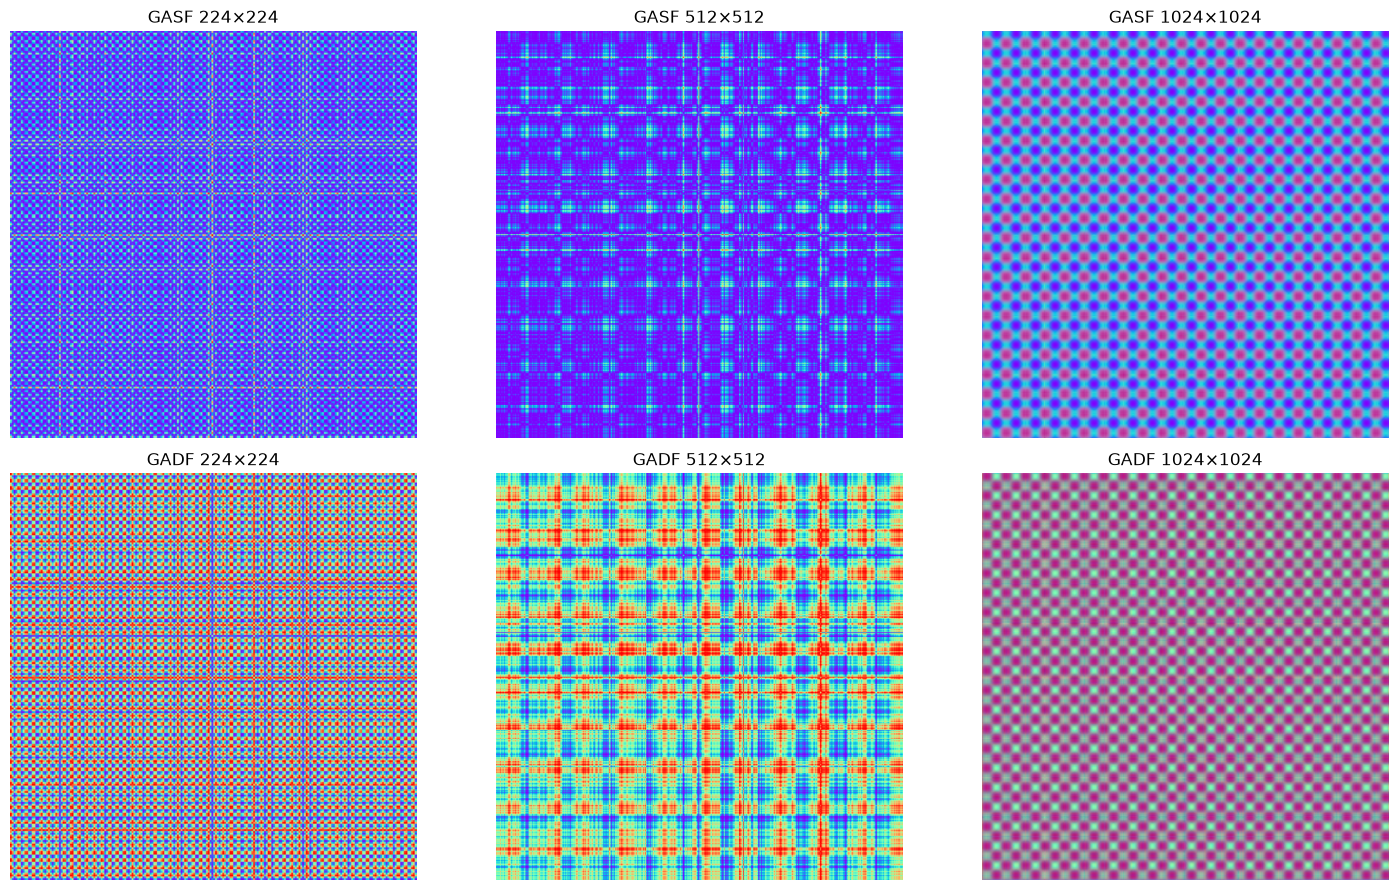

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, size in enumerate(sizes):

    gasf_transformer = GramianAngularField(
        image_size=size,
        sample_range=(-1, 1),
        method="summation",
        overlapping=False
    )

    gadf_transformer = GramianAngularField(
        image_size=size,
        sample_range=(-1, 1),
        method="difference",
        overlapping=False
    )

    gasf = gasf_transformer.fit_transform(signal_2d)[0]
    gadf = gadf_transformer.fit_transform(signal_2d)[0]

    axes[0, col].imshow(
        gasf,
        cmap="rainbow",
        origin="lower"
    )
    axes[0, col].set_title(f"GASF {size}×{size}")
    axes[0, col].axis("off")

    axes[1, col].imshow(
        gadf,
        cmap="rainbow",
        origin="lower"
    )
    axes[1, col].set_title(f"GADF {size}×{size}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()